# 05 · Avaliação nos eventos extremos

Compara todos os modelos (persistência, Ridge, gradient boosting, MLP, GRU) no **período de teste** e em cada **evento** (set/2023, nov/2023, mai/2024):

- erro de **pico** (cm e %): quanto o modelo subestimou/superestimou a cota máxima;
- erro de **horário do pico** (h; positivo = previsão atrasada);
- **`cobertura_%`** (horas da janela que puderam ser avaliadas) e **`pico_perto_de_lacuna`**: se `True`, o sensor da estação falhou ao lado do pico, e o "pico observado" é menor que o real. Nesses casos o erro de pico **não** é confiável;
- acerto na passagem da **cota de alerta**, se `ALERT_LEVEL_CM` estiver preenchido em `config.py` (POD, FAR, CSI).

As previsões são alinhadas ao instante previsto (`t + h`), para comparar com a observação do mesmo momento.
Cada horizonte é avaliado nos instantes em que a cota em `t + h` existe (uma lacuna no horizonte de 24 h não apaga mais as amostras de 6 h e 12 h).

**set/2023:** o sensor de Muçum parou às 19h30 de 04/09 (2179 cm, subindo) e só voltou em 08/09; o de Encantado parou às 22h15 de 04/09 e só voltou em 23/10. O arquivo bruto da API não tem esses valores (cota e status vazios), então o pico real desse evento **não foi medido** pela telemetria e o erro de pico de set/2023 não é avaliável.

In [1]:
import os, sys
sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data, features, metrics, pipeline
plt.rcParams["figure.figsize"] = (11, 3.4)
plt.rcParams["axes.grid"] = True

MODELOS = ["persistencia", "ridge", "hgb", "mlp", "gru"]
FIG_DIR = config.OUTPUTS / "figs" / pipeline.current_tag(); FIG_DIR.mkdir(parents=True, exist_ok=True)
print("cenário atual:", pipeline.current_tag(), "(mude com USE_IMERG em config.py)")

def carregar(alvo):
    out = {}
    for m in MODELOS:
        try:
            out[m] = pipeline.load_predictions(m, alvo)
        except FileNotFoundError:
            print(f"[aviso] sem previsões de {m} para {alvo} (rode os notebooks 03/04)")
    return out

cenário atual: com_imerg (mude com USE_IMERG em config.py)


## 1. Desempenho geral no teste

In [2]:
linhas = []
for alvo in config.TARGETS:
    preds = carregar(alvo)
    for m, df in preds.items():
        t = df[df["conjunto"] == "teste"]
        if t.empty:
            continue
        H = [h for h in config.HORIZONS if f"pred_{h}h" in t]
        obs = np.column_stack([t[f"obs_{h}h"] for h in H]); prd = np.column_stack([t[f"pred_{h}h"] for h in H])
        tab = metrics.summary_table(obs, prd, t["cota_t"].to_numpy(), H).reset_index()
        tab.insert(0, "modelo", m); tab.insert(0, "estacao", alvo); linhas.append(tab)
geral = pd.concat(linhas).set_index(["estacao", "modelo", "horizonte_h"])
display(geral)
geral.to_csv(config.OUTPUTS / f"resultados_teste_{pipeline.current_tag()}.csv")

n  RMSE_cm  MAE_cm    NSE  \
estacao  modelo       horizonte_h                                  
86510000 persistencia 6            29456   54.163  30.958  0.947   
                      8            29445   66.936  38.376  0.919   
                      12           29428   87.528  48.566  0.862   
         ridge        6            29456   43.756  21.718  0.966   
                      8            29445   55.965  27.447  0.944   
                      12           29428   84.541  44.708  0.872   
         hgb          6            29456   29.162  13.604  0.985   
                      8            29445   38.924  17.939  0.973   
                      12           29428   57.027  27.294  0.942   
         mlp          6            29456   30.468  13.644  0.983   
                      8            29445   41.657  17.654  0.969   
                      12           29428   65.698  27.813  0.922   
         gru          6            29580   34.064  17.736  0.979   
                      8            29567   43.041  21.231  0.967   
                      12           29548   59.377  30.325  0.937   
86720000 persistencia 6            24923   37.212  19.888  0.951   
                      8            24894   46.660  24.765  0.922   
                      12           24854   63.121  31.650  0.857   
         ridge        6            24923   22.453  16.234  0.982   
                      8            24894   31.122  23.038  0.965   
                      12           24854   50.001  37.597  0.910   
         hgb          6            24923   16.329   8.726  0.990   
                      8            24894   21.528  11.791  0.983   
                      12           24854   33.885  17.091  0.959   
         mlp          6            24923   16.337   9.148  0.990   
                      8            24894   21.343  11.948  0.984   
                      12           24854   34.126  17.917  0.958   
         gru          6            25384   23.589  15.267  0.982   
                      8            25341   28.200  16.967  0.974   
                      12           25297   38.354  20.498  0.952   

                                   skill_vs_persist  
estacao  modelo       horizonte_h                    
86510000 persistencia 6                       0.000  
                      8                       0.000  
                      12                      0.000  
         ridge        6                       0.347  
                      8                       0.301  
                      12                      0.067  
         hgb          6                       0.710  
                      8                       0.662  
                      12                      0.576  
         mlp          6                       0.684  
                      8                       0.613  
                      12                      0.437  
         gru          6                       0.603  
                      8                       0.585  
                      12                      0.538  
86720000 persistencia 6                       0.000  
                      8                       0.000  
                      12                      0.000  
         ridge        6                       0.636  
                      8                       0.555  
                      12                      0.373  
         hgb          6                       0.807  
                      8                       0.787  
                      12                      0.712  
         mlp          6                       0.807  
                      8                       0.791  
                      12                      0.708  
         gru          6                       0.648  
                      8                       0.676  
                      12                      0.651

## 2. Por evento: pico, horário do pico e alerta

In [3]:
linhas = []
for alvo in config.TARGETS:
    preds = carregar(alvo)
    limiar = config.ALERT_LEVEL_CM.get(alvo)
    for m, df in preds.items():
        for h in config.HORIZONS:
            obs = metrics.as_series(df.index, df[f"obs_{h}h"], h)
            prd = metrics.as_series(df.index, df[f"pred_{h}h"], h)
            for ev, (ini, fim) in config.EVENTS.items():
                st = metrics.event_stats(obs, prd, ini, fim)
                if not st:
                    continue
                if limiar is not None:
                    st.update(metrics.alert_scores(obs.loc[ini:fim], prd.loc[ini:fim], limiar))
                linhas.append({"estacao": alvo, "modelo": m, "horizonte_h": h, "evento": ev, **st})
eventos = pd.DataFrame(linhas).set_index(["estacao", "evento", "horizonte_h", "modelo"]).round(2)
display(eventos)
eventos.to_csv(config.OUTPUTS / f"resultados_eventos_{pipeline.current_tag()}.csv")
if all(v is None for v in config.ALERT_LEVEL_CM.values()):
    print("Obs.: ALERT_LEVEL_CM vazio em config.py -> colunas de alerta (POD/FAR/CSI) não calculadas.")

pico_obs_cm  pico_prev_cm  \
estacao  evento   horizonte_h modelo                                    
86510000 set/2023 6           persistencia      2149.33       1180.50   
         nov/2023 6           persistencia      2297.50       2297.50   
         mai/2024 6           persistencia      2552.50       2552.50   
         set/2023 8           persistencia      2149.33        844.00   
         nov/2023 8           persistencia      2297.50       2297.50   
...                                                 ...           ...   
86720000 nov/2023 8           gru               2059.25       2233.23   
         mai/2024 8           gru               1873.00       1774.52   
         set/2023 12          gru               1440.25        808.46   
         nov/2023 12          gru               2059.25       2451.30   
         mai/2024 12          gru               1873.00       1818.51   

                                            erro_pico_cm  erro_pico_%  \
estacao  evento   horizonte_h modelo                                    
86510000 set/2023 6           persistencia       -968.83       -45.08   
         nov/2023 6           persistencia          0.00         0.00   
         mai/2024 6           persistencia          0.00         0.00   
         set/2023 8           persistencia      -1305.33       -60.73   
         nov/2023 8           persistencia          0.00         0.00   
...                                                  ...          ...   
86720000 nov/2023 8           gru                 173.98         8.45   
         mai/2024 8           gru                 -98.48        -5.26   
         set/2023 12          gru                -631.79       -43.87   
         nov/2023 12          gru                 392.05        19.04   
         mai/2024 12          gru                 -54.49        -2.91   

                                            erro_horario_h  RMSE_evento_cm  \
estacao  evento   horizonte_h modelo                                         
86510000 set/2023 6           persistencia             0.0          201.93   
         nov/2023 6           persistencia             6.0          120.87   
         mai/2024 6           persistencia             6.0          162.81   
         set/2023 8           persistencia             0.0          239.67   
         nov/2023 8           persistencia             8.0          158.34   
...                                                    ...             ...   
86720000 nov/2023 8           gru                     -7.0           60.57   
         mai/2024 8           gru                      1.0          124.99   
         set/2023 12          gru                      0.0          135.74   
         nov/2023 12          gru                     -4.0           88.94   
         mai/2024 12          gru                      9.0          153.14   

                                            cobertura_%  pico_perto_de_lacuna  
estacao  evento   horizonte_h modelo                                           
86510000 set/2023 6           persistencia        58.33                  True  
         nov/2023 6           persistencia       100.00                 False  
         mai/2024 6           persistencia       100.00                 False  
         set/2023 8           persistencia        57.64                  True  
         nov/2023 8           persistencia       100.00                 False  
...                                                 ...                   ...  
86720000 nov/2023 8           gru                100.00                 False  
         mai/2024 8           gru                 28.07                  True  
         set/2023 12          gru                 26.04                  True  
         nov/2023 12          gru                100.00                 False  
         mai/2024 12          gru                 26.75                  True  

[90 rows x 8 columns]

Obs.: ALERT_LEVEL_CM vazio em config.py -> colunas de alerta (POD/FAR/CSI) não calculadas.


## 2b. Efeito dos limites contra extrapolação

Mesmos instantes, mesmo modelo treinado: previsão **sem limites** × **com limites** (entradas e variação prevista
restritas à faixa do treino + `config.CLIP_MARGIN`). Interessa principalmente o erro de pico em nov/2023 e mai/2024.
`delta < 0` = os limites reduziram o erro (em módulo, no caso do pico).

In [4]:
linhas = []
for alvo in config.TARGETS:
    for m, df in carregar(alvo).items():
        if m == "persistencia" or f"pred_sem_limite_{config.HORIZONS[0]}h" not in df:
            continue
        te = df[df["conjunto"] == "teste"]
        for h in config.HORIZONS:
            obs = metrics.as_series(df.index, df[f"obs_{h}h"], h)
            for versao, col in (("sem", f"pred_sem_limite_{h}h"), ("com", f"pred_{h}h")):
                prd = metrics.as_series(df.index, df[col], h)
                linhas.append({"estacao": alvo, "modelo": m, "horizonte_h": h, "evento": "teste (todo)", "versao": versao,
                               "RMSE_cm": metrics.rmse(te[f"obs_{h}h"], te[col])})
                for ev, (ini, fim) in config.EVENTS.items():
                    st = metrics.event_stats(obs, prd, ini, fim)
                    if st:
                        linhas.append({"estacao": alvo, "modelo": m, "horizonte_h": h, "evento": ev, "versao": versao,
                                       "RMSE_cm": st["RMSE_evento_cm"], "pico_prev_cm": st["pico_prev_cm"],
                                       "erro_pico_cm": st["erro_pico_cm"], "pico_obs_cm": st["pico_obs_cm"]})
if linhas:
    efeito = (pd.DataFrame(linhas)
              .pivot_table(index=["estacao", "evento", "horizonte_h", "modelo"], columns="versao",
                           values=["RMSE_cm", "pico_prev_cm", "erro_pico_cm"], dropna=False))
    efeito.columns = [f"{a}_{b}" for a, b in efeito.columns]
    efeito["delta_RMSE_cm"] = efeito["RMSE_cm_com"] - efeito["RMSE_cm_sem"]
    efeito["delta_abs_erro_pico_cm"] = efeito["erro_pico_cm_com"].abs() - efeito["erro_pico_cm_sem"].abs()
    efeito = efeito.round(1)
    display(efeito.loc[(slice(None), ["nov/2023", "mai/2024"]), :])
    efeito.to_csv(config.OUTPUTS / f"efeito_limites_{pipeline.current_tag()}.csv")
else:
    print("Previsões sem a coluna pred_sem_limite_*: rode os notebooks 03/04 de novo.")

RMSE_cm_com  RMSE_cm_sem  \
estacao  evento   horizonte_h modelo                             
86510000 nov/2023 6           gru            47.4         47.6   
                              hgb            32.4         32.4   
                              mlp            54.6         55.9   
                              ridge          39.2         38.8   
                  8           gru            60.3         60.5   
                              hgb            45.2         45.2   
                              mlp            76.8         81.1   
                              ridge          53.3         52.9   
                  12          gru            85.5         85.7   
                              hgb            81.4         81.4   
                              mlp           124.0        134.2   
                              ridge          91.4         91.1   
86720000 nov/2023 6           gru            47.0         47.3   
                              hgb            36.2         36.2   
                              mlp            43.4         44.5   
                              ridge          38.4         38.2   
                  8           gru            60.6         60.9   
                              hgb            49.3         49.3   
                              mlp            58.7         60.3   
                              ridge          55.9         55.6   
                  12          gru            88.9         89.4   
                              hgb            81.6         81.6   
                              mlp            93.8         96.0   
                              ridge          96.1         95.6   
86510000 mai/2024 6           gru           126.5        126.6   
                              hgb           121.4        121.4   
                              mlp           129.1        130.4   
                              ridge         184.6        182.5   
                  8           gru           157.3        157.4   
                              hgb           169.1        169.1   
                              mlp           189.3        189.8   
                              ridge         243.8        243.7   
                  12          gru           206.0        206.0   
                              hgb           234.0        234.0   
                              mlp           330.8        331.9   
                              ridge         389.1        398.2   
86720000 mai/2024 6           gru           110.9        110.9   
                              hgb           121.6        121.6   
                              mlp           113.1        112.7   
                              ridge         134.4        133.8   
                  8           gru           125.0        125.0   
                              hgb           147.7        147.7   
                              mlp           135.5        135.1   
                              ridge         170.9        169.4   
                  12          gru           153.1        153.1   
                              hgb           188.9        188.9   
                              mlp           183.0        183.2   
                              ridge         216.5        216.2   

                                      erro_pico_cm_com  erro_pico_cm_sem  \
estacao  evento   horizonte_h modelo                                       
86510000 nov/2023 6           gru                 40.7              45.7   
                              hgb                 98.0              98.0   
                              mlp                140.5             133.9   
                              ridge              134.4             132.0   
                  8           gru                134.9             134.9   
                              hgb                219.7             219.7   
                              mlp                233.8             226.6   
                              ridge              148.

## 3. Gráficos: observado × previsto

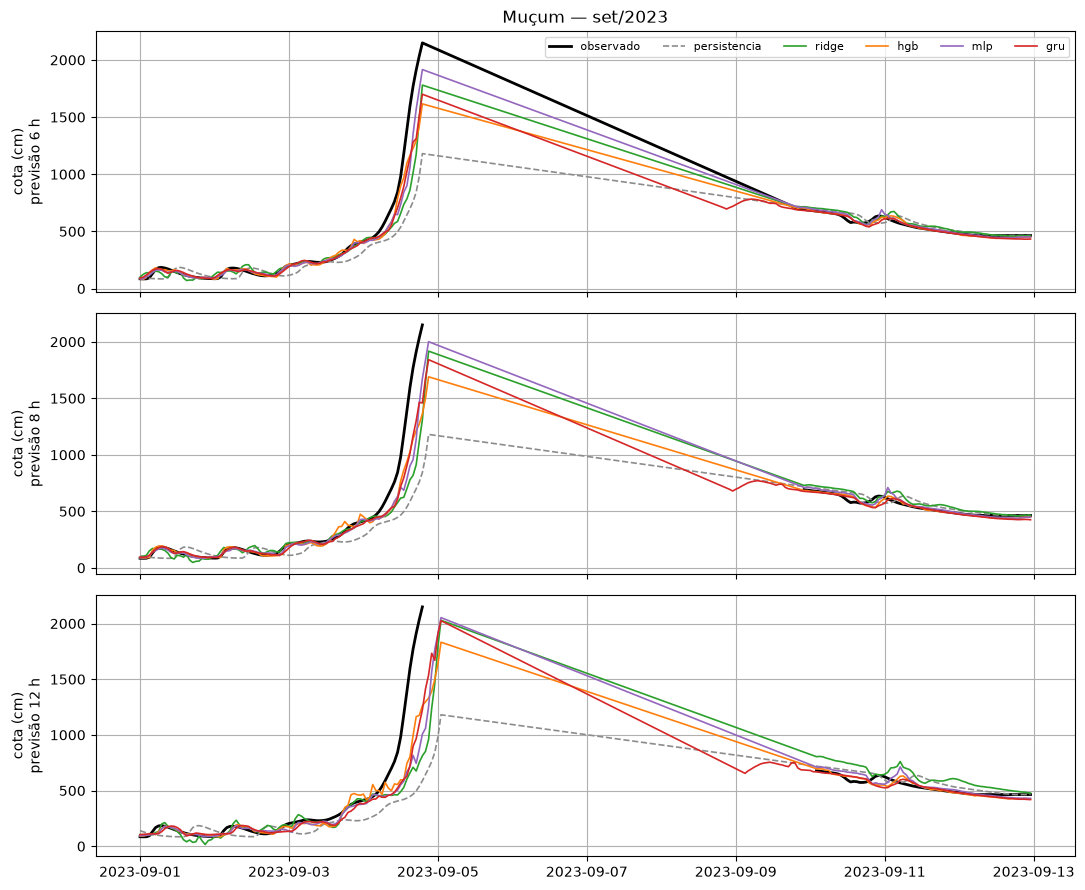

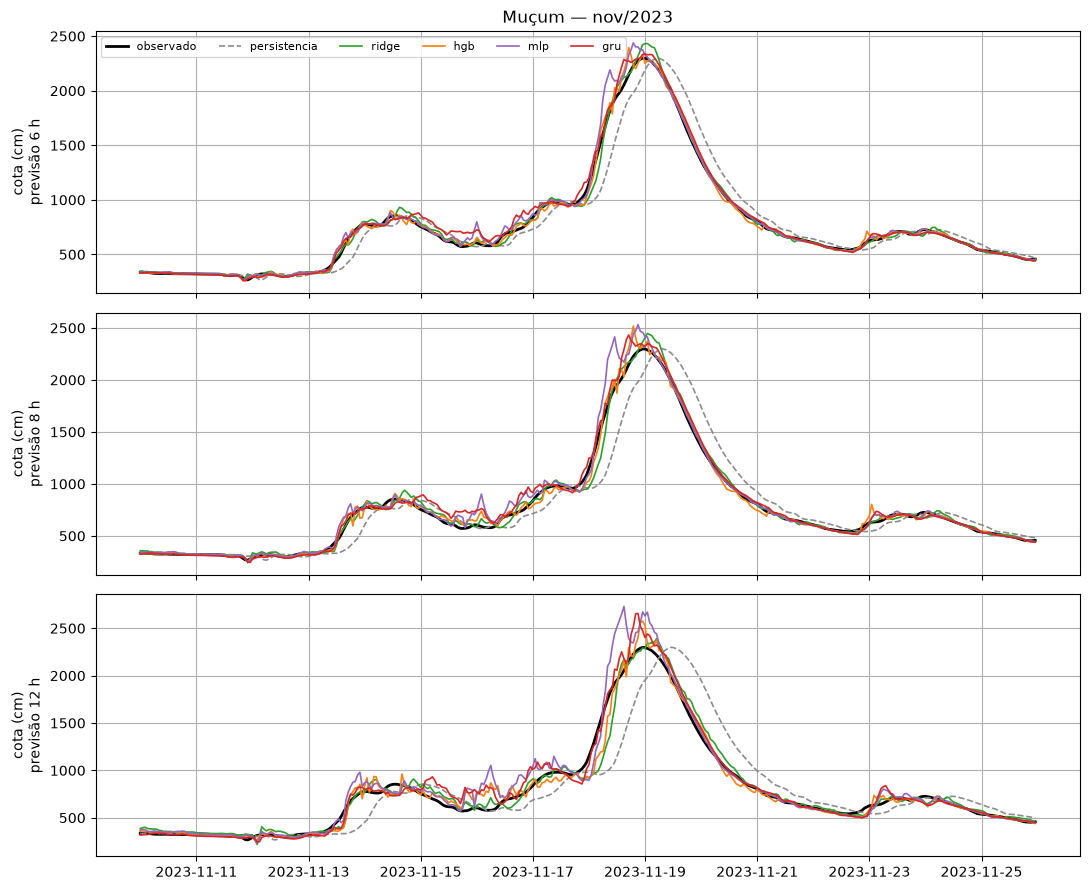

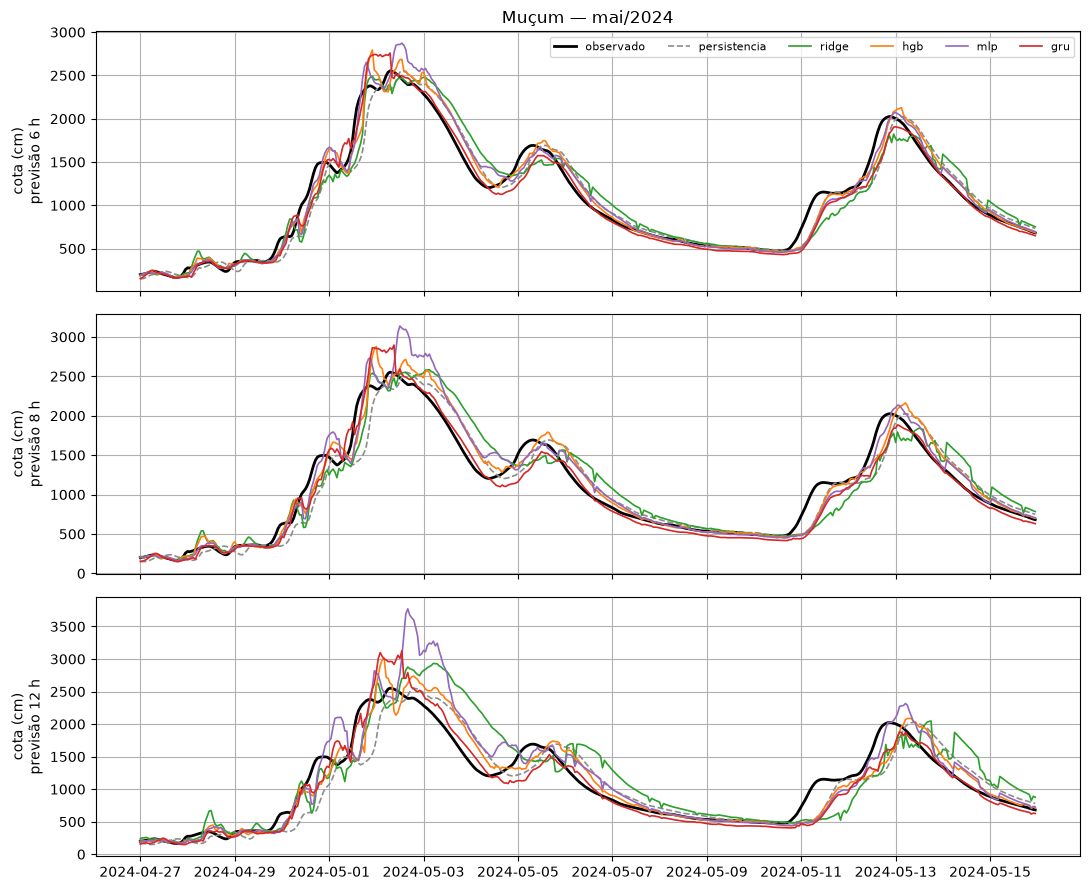

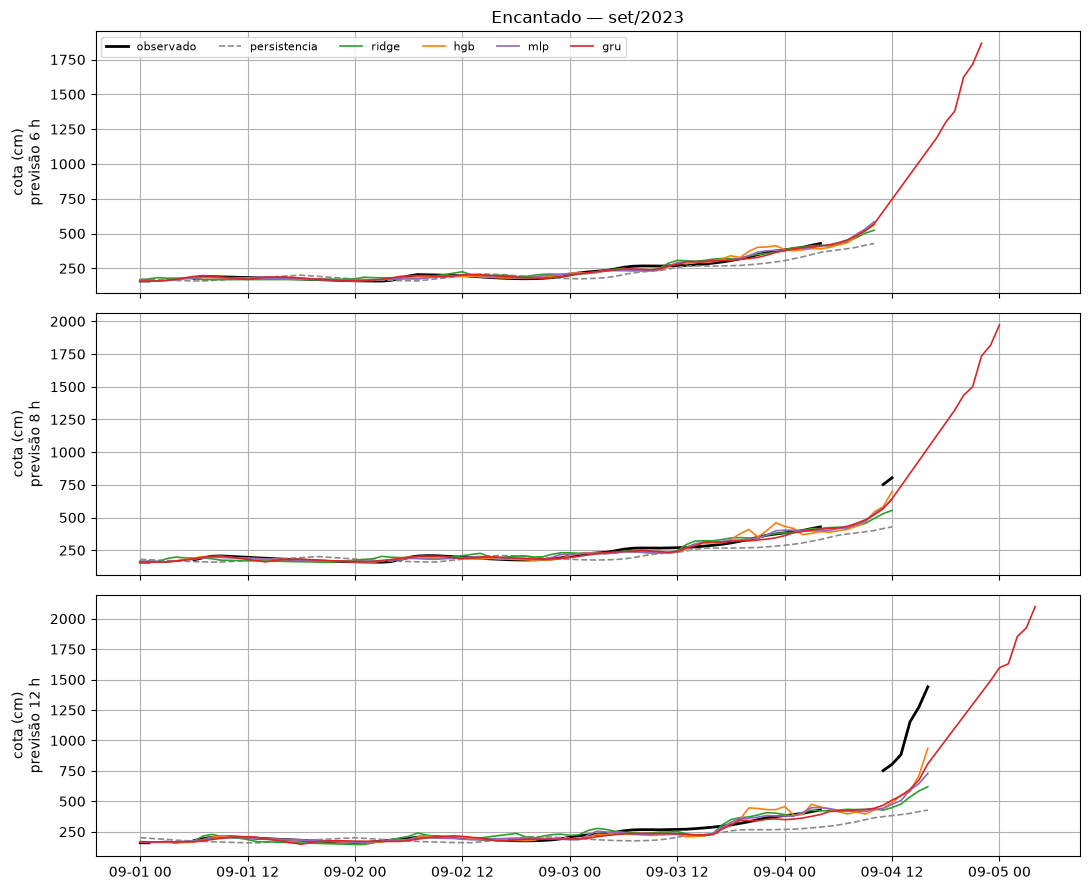

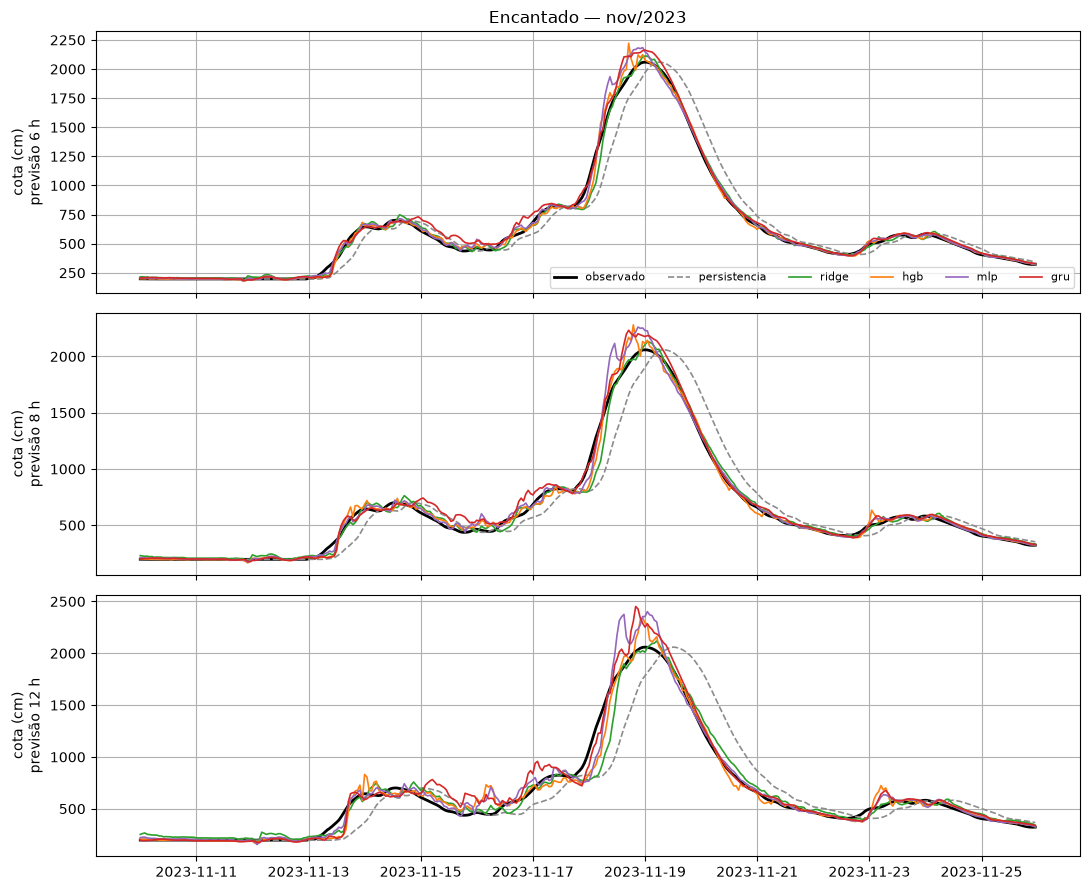

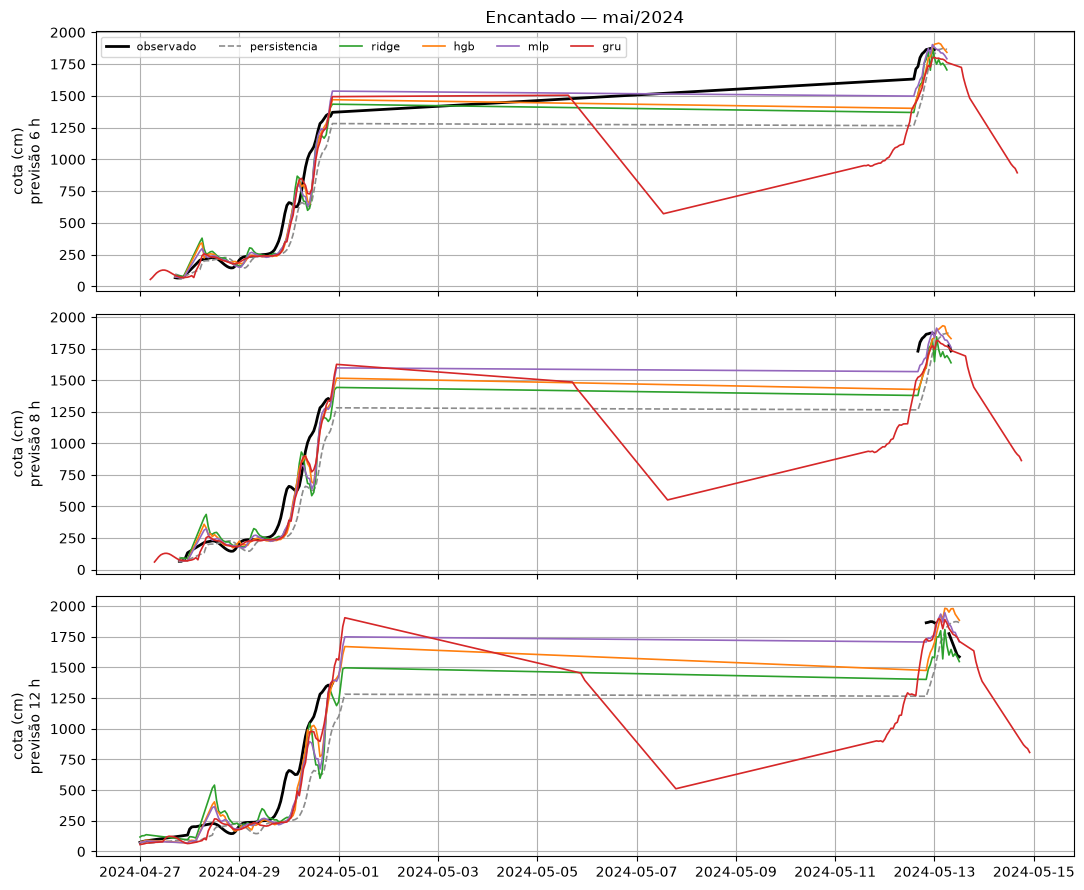

In [5]:
cores = {"persistencia": "0.55", "ridge": "tab:green", "hgb": "tab:orange", "mlp": "tab:purple", "gru": "tab:red"}
for alvo in config.TARGETS:
    preds = carregar(alvo)
    if not preds:
        continue
    for ev, (ini, fim) in config.EVENTS.items():
        fig, axes = plt.subplots(len(config.HORIZONS), 1, figsize=(11, 3.0 * len(config.HORIZONS)), sharex=True)
        for ax, h in zip(np.atleast_1d(axes), config.HORIZONS):
            ref = next(iter(preds.values()))
            obs = metrics.as_series(ref.index, ref[f"obs_{h}h"], h).loc[ini:fim]
            if obs.empty:
                continue
            ax.plot(obs.index, obs, color="k", lw=2, label="observado")
            for m, df in preds.items():
                s = metrics.as_series(df.index, df[f"pred_{h}h"], h).loc[ini:fim]
                ax.plot(s.index, s, lw=1.2, color=cores[m], ls="--" if m == "persistencia" else "-", label=m)
            ax.set_ylabel(f"cota (cm)\nprevisão {h} h")
        np.atleast_1d(axes)[0].legend(ncol=6, fontsize=8)
        np.atleast_1d(axes)[0].set_title(f"{config.STATIONS[alvo]['nome']} — {ev}")
        plt.tight_layout()
        fig.savefig(FIG_DIR / f"evento_{alvo}_{ev.replace('/', '-')}.png", dpi=150)
        plt.show()

## 4. Com × sem IMERG (rode os notebooks 03–05 nos dois cenários antes)

Compara, **nos mesmos instantes**, o erro dos modelos sem e com a chuva do IMERG. `delta_RMSE < 0` = o IMERG ajudou.
Para gerar o cenário com IMERG: `USE_IMERG = True` em `config.py`, reinicie o kernel e rode 03 → 05 de novo.

In [6]:
linhas = []
for alvo in config.TARGETS:
    for m in MODELOS:
        try:
            a = pipeline.load_predictions(m, alvo, tag="sem_imerg"); b = pipeline.load_predictions(m, alvo, tag="com_imerg")
        except FileNotFoundError:
            continue
        idx = a.index.intersection(b.index)
        a, b = a.loc[idx], b.loc[idx]
        a, b = a[a["conjunto"] == "teste"], b[b["conjunto"] == "teste"]
        for h in config.HORIZONS:
            o = a[f"obs_{h}h"]
            linhas.append({"estacao": alvo, "modelo": m, "horizonte_h": h, "n": len(a),
                           "RMSE_sem": metrics.rmse(o, a[f"pred_{h}h"]), "RMSE_com": metrics.rmse(o, b[f"pred_{h}h"])})
if linhas:
    comp = pd.DataFrame(linhas); comp["delta_RMSE_cm"] = comp["RMSE_com"] - comp["RMSE_sem"]
    comp["delta_%"] = 100 * comp["delta_RMSE_cm"] / comp["RMSE_sem"]
    display(comp.set_index(["estacao", "modelo", "horizonte_h"]).round(2))
    comp.to_csv(config.OUTPUTS / "comparacao_com_sem_imerg.csv", index=False)
else:
    print("Ainda falta rodar os dois cenários (sem_imerg e com_imerg).")

n  RMSE_sem  RMSE_com  delta_RMSE_cm  \
estacao  modelo       horizonte_h                                             
86510000 persistencia 6            29464     54.16     54.16           0.00   
                      8            29464     66.94     66.94           0.00   
                      12           29464     87.53     87.53           0.00   
         ridge        6            29464     43.76     43.76          -0.01   
                      8            29464     55.89     55.96           0.08   
                      12           29464     83.64     84.54           0.90   
         hgb          6            29464     30.22     29.16          -1.06   
                      8            29464     40.55     38.92          -1.62   
                      12           29464     60.06     57.03          -3.03   
         mlp          6            29464     30.92     30.47          -0.45   
                      8            29464     41.54     41.66           0.11   
                      12           29464     63.53     65.70           2.17   
         gru          6            29590     33.56     34.06           0.50   
                      8            29590     43.20     43.04          -0.16   
                      12           29590     62.08     59.38          -2.70   
86720000 persistencia 6            24976     37.21     37.21           0.00   
                      8            24976     46.66     46.66           0.00   
                      12           24976     63.12     63.12           0.00   
         ridge        6            24976     22.38     22.45           0.07   
                      8            24976     30.98     31.12           0.14   
                      12           24976     49.71     50.00           0.29   
         hgb          6            24976     16.63     16.33          -0.30   
                      8            24976     22.14     21.53          -0.61   
                      12           24976     35.02     33.88          -1.13   
         mlp          6            24976     16.12     16.34           0.21   
                      8            24976     21.31     21.34           0.04   
                      12           24976     34.58     34.13          -0.45   
         gru          6            25464     25.10     23.59          -1.51   
                      8            25464     29.78     28.20          -1.58   
                      12           25464     41.23     38.35          -2.87   

                                   delta_%  
estacao  modelo       horizonte_h           
86510000 persistencia 6               0.00  
                      8               0.00  
                      12              0.00  
         ridge        6              -0.02  
                      8               0.14  
                      12              1.08  
         hgb          6              -3.49  
                      8              -4.00  
                      12             -5.04  
         mlp          6              -1.45  
                      8               0.27  
                      12              3.42  
         gru          6               1.49  
                      8              -0.38  
                      12             -4.36  
86720000 persistencia 6               0.00  
                      8               0.00  
                      12              0.00  
         ridge        6               0.32  
                      8               0.46  
                      12              0.59  
         hgb          6              -1.82  
                      8              -2.75  
                      12             -3.23  
         mlp          6               1.32  
                      8               0.17  
                      12             -1.31  
         gru          6              -6.02  
                      8              -5.30  
                      12             -6.97

## 5. O que levar para o artigo

- **Tabela 1** (`resultados_teste_<cenário>.csv`): RMSE/MAE/NSE/skill por modelo e horizonte.
- **Tabela 2** (`resultados_eventos_<cenário>.csv`): erro de pico e de horário por evento.
- **Figuras** em `outputs/figs/<cenário>/`.
- **Discussão:** quanto cada modelo subestima o pico em mai/2024 (acima do histórico de treino) e em que horizonte o ganho sobre a persistência desaparece.
- Se tiver boletins do SAH-Taquari dos eventos, compare **qualitativamente** as previsões oficiais de 4–6 h com as suas.